# Model 1: evaluation on the golden rides

The golden split was held out from training. These figures read the outputs of the existing evaluation stage; they do not train or select a model. If the artifacts are missing, start MLflow with `make dev-up` and run `uv run dvc repro evaluate`.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
import yaml
from sklearn.metrics import confusion_matrix
from ride_classifier.config import LABELS
from ride_classifier.viz.theme import apply_theme, heatmap_cmap, save_fig

root = Path.cwd()
if not (root / "params.yaml").exists():
    root = root.parent
metrics = json.loads((root / "artifacts/golden_metrics.json").read_text(encoding="utf-8"))
predictions = pd.read_csv(root / "artifacts/golden_predictions.csv")
params = yaml.safe_load((root / "params.yaml").read_text(encoding="utf-8"))
apply_theme()

## Golden confusion matrix

Rows are the known ride categories; columns are the model's whole-ride predictions.

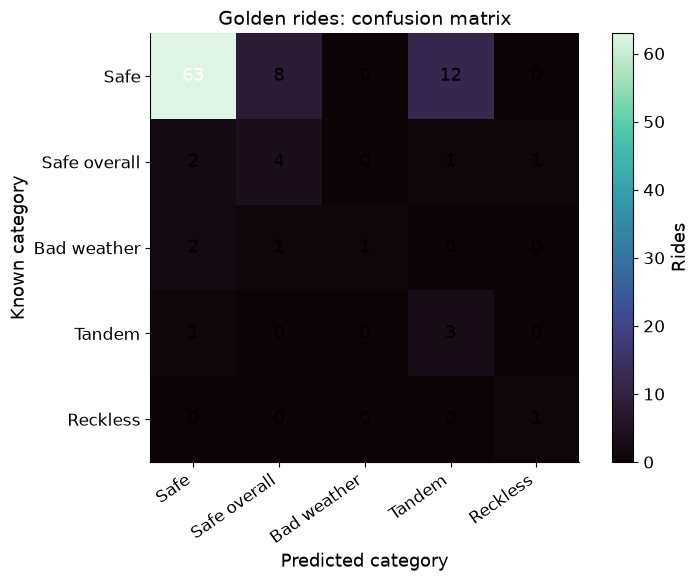

In [2]:
matrix = confusion_matrix(predictions["label"], predictions["predicted"], labels=LABELS)
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(matrix, cmap=heatmap_cmap())
for row in range(len(LABELS)):
    for col in range(len(LABELS)):
        ax.text(col, row, str(matrix[row, col]), ha="center", va="center",
                color="white" if matrix[row, col] > matrix.max() / 2 else "black")
ax.set(xticks=range(len(LABELS)), yticks=range(len(LABELS)), xticklabels=LABELS, yticklabels=LABELS,
       xlabel="Predicted category", ylabel="Known category", title="Golden rides: confusion matrix")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
fig.colorbar(image, ax=ax, label="Rides")
fig.tight_layout()
save_fig(fig, "F09", "golden_confusion_matrix")
plt.show()

## Quality gate

The trained model must clear the configured floor and, when enabled, beat both references on the same golden rides. The random reference is one seeded result, not an analytic chance level.

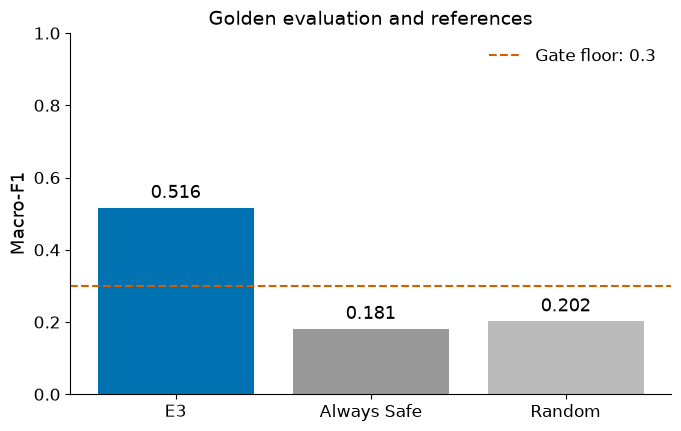

,macro_f1
E3,0.516411
Always Safe,0.181421
Random,0.202328


In [3]:
scores = pd.Series({"E3": metrics["golden_macro_f1"],
                    "Always Safe": metrics["golden_ref_majority_macro_f1"],
                    "Random": metrics["golden_ref_random_macro_f1"]})
floor = params["evaluate"]["gate"]["min_macro_f1"]
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(scores.index, scores.values, color=["#0072B2", "#999999", "#BBBBBB"])
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.axhline(floor, color="#D55E00", linestyle="--", label=f"Gate floor: {floor:g}")
ax.set(ylabel="Macro-F1", ylim=(0, 1), title="Golden evaluation and references")
ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "F10", "golden_quality_gate")
plt.show()
scores.to_frame("macro_f1")

## Reckless and counterfactual categories

The golden split contains very few Reckless rides. Counts are shown alongside rates to make that limitation visible. Here a false alarm means a ride in a counterfactual category predicted as Reckless; it does not mean a fall alarm.

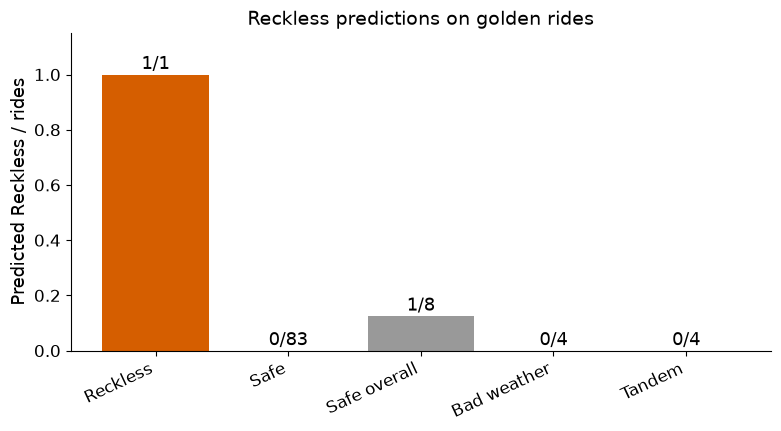

,Known category,Predicted Reckless,Rides,Rate
0,Reckless,1,1,1.000
1,Safe,0,83,0.000
2,Safe overall,1,8,0.125
3,Bad weather,0,4,0.000
4,Tandem,0,4,0.000


In [4]:
categories = ["Reckless", "Safe", "Safe overall", "Bad weather", "Tandem"]
summary = []
for category in categories:
    subset = predictions[predictions["label"] == category]
    flagged = int((subset["predicted"] == "Reckless").sum())
    summary.append({"Known category": category, "Predicted Reckless": flagged, "Rides": len(subset),
                    "Rate": flagged / len(subset) if len(subset) else float("nan")})
summary = pd.DataFrame(summary)
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(summary["Known category"], summary["Rate"], color=["#D55E00"] + ["#999999"] * 4)
for bar, row in zip(bars, summary.itertuples(index=False), strict=True):
    ax.annotate(f"{row[1]}/{row[2]}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 4), textcoords="offset points", ha="center")
ax.set(ylabel="Predicted Reckless / rides", ylim=(0, 1.15), title="Reckless predictions on golden rides")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
fig.tight_layout()
save_fig(fig, "F11", "golden_reckless_predictions")
plt.show()
summary